# Model 2 – 02 Train (MobileNetV3-Large, 7 classes → HAND / LEG / OTHER)
**Purpose:** Train the first anatomical-region model on the 7 fine classes; HAND/LEG/OTHER = sum of fine-class probabilities.
**Inputs:** outputs/model2/manifest_split.csv, outputs/model2/cache_224.npz (from 01_data_preparation)
**Outputs:** outputs/model2/mobilenetv3_model2_best.pt, training history, test metrics

In [1]:
# ===== SETTINGS =====
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
OUT_DIR    = DRIVE_ROOT / 'outputs' / 'model2'
MANIFEST   = OUT_DIR / 'manifest_split.csv'
CACHE      = OUT_DIR / 'cache_224.npz'
MODEL_PATH = OUT_DIR / 'mobilenetv3_model2_best.pt'

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 15
LR = 1e-4
PATIENCE = 4              # early stopping: stop if val macro-F1 does not improve for 4 epochs

# Augmentation strength
P_LOWRES = 0.3            # chance of down-then-up resizing (against the ChestMNIST low-resolution shortcut)
P_JPEG   = 0.3            # chance of JPEG re-compression (against the PNG-vs-JPG shortcut)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, torch, random
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '(no GPU – change runtime!)')

df = pd.read_csv(MANIFEST)
cache = np.load(CACHE, allow_pickle=True)
X = cache['images']
assert (cache['paths'][df.cache_idx] == df.path).all(), 'Manifest and cache do not match!'
print('Manifest:', df.shape, ' Cache:', X.shape)

Mounted at /content/drive
Device: cuda Tesla T4
Manifest: (3682, 14)  Cache: (3712, 224, 224)


In [3]:
CLASSES = sorted(df['label'].unique())                      # the 7 training classes (fixed order)
SHORT = {c: c.split(' - ')[0] for c in CLASSES}            # short names for plots, e.g. 'Hip to knee'
SUPER = {c: ('OTHER' if c == 'OTHER' else
             'LEG' if c.split(' - ')[0] in ('Hip to knee', 'Knee to ankle', 'Foot and ankle') else 'HAND')
         for c in CLASSES}
df['y'] = df['label'].map({c: i for i, c in enumerate(CLASSES)})

for i, c in enumerate(CLASSES):
    print(i, f'{SHORT[c]:18s} -> {SUPER[c]:5s}', dict(df[df.y == i].split.value_counts()))

0 Elbow to wrist     -> HAND  {'train': np.int64(442), 'test': np.int64(83), 'val': np.int64(82)}
1 Foot and ankle     -> LEG   {'train': np.int64(78), 'val': np.int64(15), 'test': np.int64(12)}
2 Hip to knee        -> LEG   {'train': np.int64(174), 'test': np.int64(35), 'val': np.int64(30)}
3 Knee to ankle      -> LEG   {'train': np.int64(208), 'val': np.int64(51), 'test': np.int64(40)}
4 OTHER              -> OTHER {'train': np.int64(345), 'test': np.int64(70), 'val': np.int64(69)}
5 Shoulder to elbow  -> HAND  {'train': np.int64(360), 'test': np.int64(75), 'val': np.int64(68)}
6 Wrist and hand     -> HAND  {'train': np.int64(1031), 'val': np.int64(210), 'test': np.int64(204)}


In [4]:
import io
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet statistics

def degrade(img):
    """Randomly lower the resolution and/or add JPEG artefacts, so image quality cannot reveal the class."""
    if random.random() < P_LOWRES:
        s = random.randint(64, 160)
        img = img.resize((s, s), Image.BILINEAR).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    if random.random() < P_JPEG:
        buf = io.BytesIO(); img.save(buf, format='JPEG', quality=random.randint(30, 90))
        img = Image.open(buf).convert('L')
    return img

to_model = [T.ToTensor(), T.Lambda(lambda t: t.repeat(3, 1, 1)), T.Normalize(MEAN, STD)]  # gray -> 3 channels

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(),             # left/right does not change the body region
    T.RandomRotation(20),                 # many dataset images are rotated
    T.ColorJitter(brightness=0.2, contrast=0.2),
    *to_model])
eval_tf = T.Compose(to_model)             # val/test: no augmentation

class XrayDataset(Dataset):
    def __init__(self, frame, train):
        self.idx, self.y, self.train = frame.cache_idx.values, frame.y.values, train
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        img = Image.fromarray(X[self.idx[i]])
        img = train_tf(degrade(img)) if self.train else eval_tf(img)
        return img, self.y[i]

splits = {s: df[df.split == s].reset_index(drop=True) for s in ['train', 'val', 'test']}
loaders = {s: DataLoader(XrayDataset(splits[s], train=(s == 'train')), batch_size=BATCH_SIZE,
                         shuffle=(s == 'train'), num_workers=2, pin_memory=True)
           for s in splits}
print({s: len(f) for s, f in splits.items()})

{'train': 2638, 'val': 525, 'test': 519}


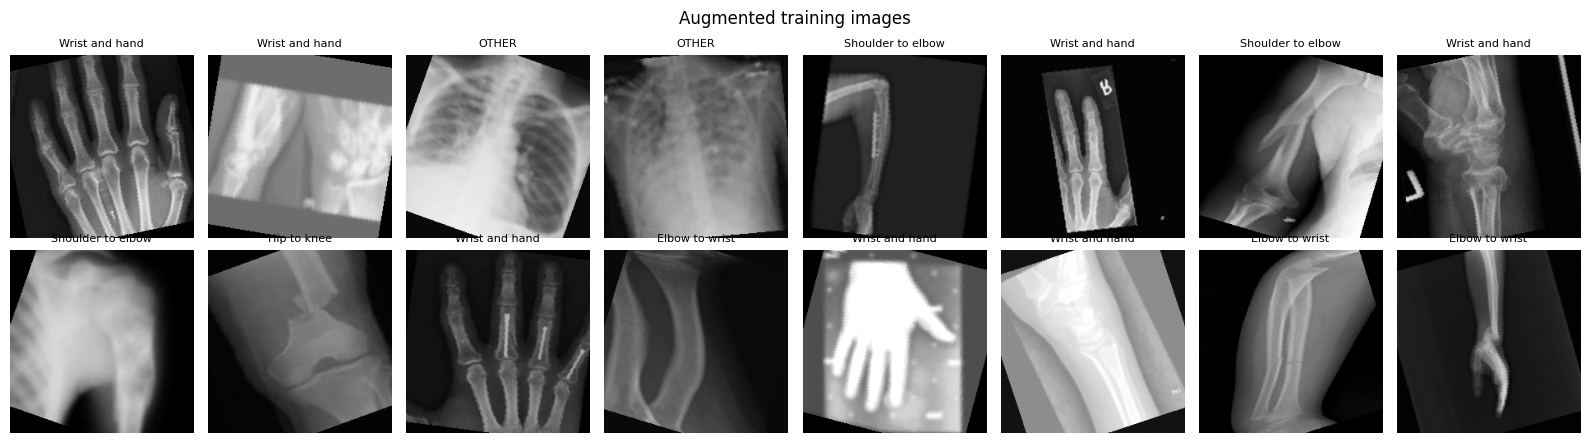

One batch: torch.Size([64, 3, 224, 224]) torch.Size([64])


In [5]:
import matplotlib.pyplot as plt

ds = XrayDataset(splits['train'], train=True)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, np.random.RandomState(SEED).choice(len(ds), 16, replace=False)):
    img, y = ds[i]
    ax.imshow(img[0] * STD[0] + MEAN[0], cmap='gray', vmin=0, vmax=1)   # undo normalisation for display
    ax.set_title(SHORT[CLASSES[y]], fontsize=8); ax.axis('off')
plt.suptitle('Augmented training images'); plt.tight_layout(); plt.show()

xb, yb = next(iter(loaders['train']))
print('One batch:', xb.shape, yb.shape)   # expect [64, 3, 224, 224] and [64]

## Part B – Training
MobileNetV3-Large (ImageNet weights), all layers fine-tuned, AdamW + cosine learning-rate schedule,
class-weighted loss (sqrt-balanced, for the 1,031 vs 78 imbalance), mixed precision.
Best epoch chosen by validation macro-F1 (treats every class equally, unlike accuracy).

In [6]:
import torch.nn as nn
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

model = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(CLASSES))   # 1000 -> 7 outputs
model = model.to(device)

counts = splits['train'].y.value_counts().sort_index().values
w = (counts.sum() / (len(CLASSES) * counts)) ** 0.5          # rare classes get a higher weight (softened)
w = w / w.mean()
print('Class weights:', {SHORT[c]: round(float(x), 2) for c, x in zip(CLASSES, w)})

criterion = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 114MB/s] 


Class weights: {'Elbow to wrist': 0.75, 'Foot and ankle': 1.79, 'Hip to knee': 1.2, 'Knee to ankle': 1.09, 'OTHER': 0.85, 'Shoulder to elbow': 0.83, 'Wrist and hand': 0.49}


In [7]:
from sklearn.metrics import f1_score
import torch.nn.functional as F

def run_epoch(loader):
    """One pass over the training data."""
    model.train(); total = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            loss = criterion(model(xb), yb)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        total += loss.item() * len(yb)
    return total / len(loader.dataset)

@torch.no_grad()
def predict(loader):
    """Return class probabilities and true labels for a whole split."""
    model.eval(); probs, ys = [], []
    for xb, yb in loader:
        with torch.amp.autocast('cuda'):
            probs.append(F.softmax(model(xb.to(device)).float(), dim=1).cpu())
        ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

In [8]:
import time
history, best_f1, wait = [], -1, 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = run_epoch(loaders['train'])
    scheduler.step()
    p_val, y_val = predict(loaders['val'])
    val_acc = (p_val.argmax(1) == y_val).mean()
    val_f1 = f1_score(y_val, p_val.argmax(1), average='macro')
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_acc': val_acc, 'val_macro_f1': val_f1})
    print(f'Epoch {epoch:2d} | loss {train_loss:.3f} | val acc {val_acc:.3f} | val macro-F1 {val_f1:.3f} | {time.time()-t0:.0f}s')

    if val_f1 > best_f1:                       # new best -> save
        best_f1, wait = val_f1, 0
        torch.save({'state_dict': model.state_dict(), 'classes': CLASSES, 'super': SUPER,
                    'img_size': IMG_SIZE, 'mean': MEAN, 'std': STD, 'epoch': epoch}, MODEL_PATH)
        print('   ✓ saved best model')
    else:
        wait += 1
        if wait >= PATIENCE:
            print('Early stopping.'); break

pd.DataFrame(history).to_csv(OUT_DIR / 'history_mobilenetv3.csv', index=False)
print('Best val macro-F1:', round(best_f1, 4))

Epoch  1 | loss 1.475 | val acc 0.697 | val macro-F1 0.523 | 17s
   ✓ saved best model
Epoch  2 | loss 0.771 | val acc 0.741 | val macro-F1 0.644 | 9s
   ✓ saved best model
Epoch  3 | loss 0.493 | val acc 0.730 | val macro-F1 0.593 | 9s
Epoch  4 | loss 0.353 | val acc 0.813 | val macro-F1 0.744 | 9s
   ✓ saved best model
Epoch  5 | loss 0.278 | val acc 0.874 | val macro-F1 0.839 | 9s
   ✓ saved best model
Epoch  6 | loss 0.230 | val acc 0.851 | val macro-F1 0.809 | 9s
Epoch  7 | loss 0.202 | val acc 0.895 | val macro-F1 0.861 | 9s
   ✓ saved best model
Epoch  8 | loss 0.169 | val acc 0.907 | val macro-F1 0.880 | 9s
   ✓ saved best model
Epoch  9 | loss 0.166 | val acc 0.899 | val macro-F1 0.870 | 9s
Epoch 10 | loss 0.141 | val acc 0.909 | val macro-F1 0.883 | 9s
   ✓ saved best model
Epoch 11 | loss 0.126 | val acc 0.914 | val macro-F1 0.890 | 11s
   ✓ saved best model
Epoch 12 | loss 0.118 | val acc 0.918 | val macro-F1 0.899 | 11s
   ✓ saved best model
Epoch 13 | loss 0.119 | val acc

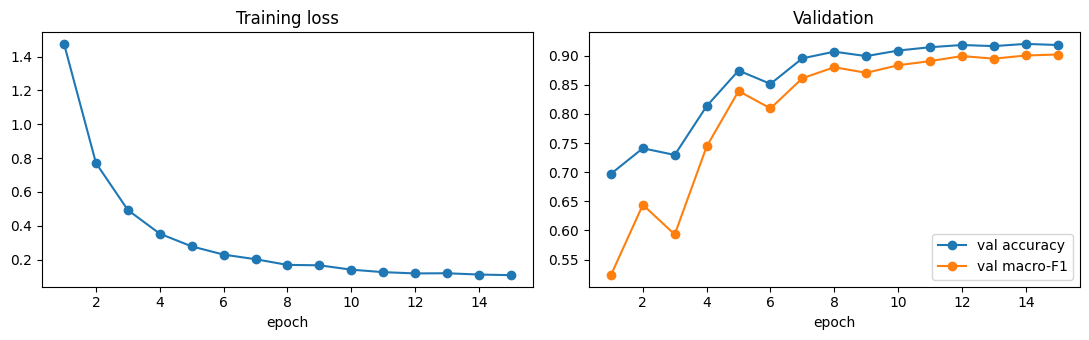

In [9]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.epoch, h.train_loss, marker='o'); ax[0].set_title('Training loss'); ax[0].set_xlabel('epoch')
ax[1].plot(h.epoch, h.val_acc, marker='o', label='val accuracy')
ax[1].plot(h.epoch, h.val_macro_f1, marker='o', label='val macro-F1')
ax[1].set_title('Validation'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

## Part C – Test evaluation (519 unseen images)
7-class results, then HAND/LEG/OTHER (sum of sub-class probabilities), 95% confidence interval,
subgroup checks (OTHER per source, annotated vs clean), error examples, model size and speed.
Predictions are saved for the model comparison / ensemble notebook.

In [10]:
ckpt = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(ckpt['state_dict'])
print('Loaded best epoch:', ckpt['epoch'])

SUPER_NAMES = ['HAND', 'LEG', 'OTHER']
M = np.array([[SUPER[c] == s for s in SUPER_NAMES] for c in CLASSES], dtype=float)  # 7x3: which class adds to which group

def save_preds(split):
    p, y = predict(loaders[split])
    out = splits[split][['path', 'filename', 'label', 'source', 'has_colour_annotation', 'cache_idx']].copy()
    out[[f'p_{SHORT[c]}' for c in CLASSES]] = p
    ps = p @ M                                            # P(HAND), P(LEG), P(OTHER)
    out[[f'p_{s}' for s in SUPER_NAMES]] = ps
    out['pred_label'] = [CLASSES[k] for k in p.argmax(1)]
    out['true_super'] = out['label'].map(SUPER)
    out['pred_super'] = [SUPER_NAMES[k] for k in ps.argmax(1)]
    out.to_csv(OUT_DIR / f'preds_mobilenetv3_{split}.csv', index=False)
    return out, p, y

val_out,  p_val,  y_val  = save_preds('val')
test_out, p_test, y_test = save_preds('test')
print('Saved val/test predictions.')

Loaded best epoch: 15
Saved val/test predictions.


                   precision    recall  f1-score   support

   Elbow to wrist      0.857     0.867     0.862        83
   Foot and ankle      0.750     0.750     0.750        12
      Hip to knee      0.938     0.857     0.896        35
    Knee to ankle      0.946     0.875     0.909        40
            OTHER      0.985     0.943     0.964        70
Shoulder to elbow      0.896     0.920     0.908        75
   Wrist and hand      0.938     0.966     0.952       204

         accuracy                          0.921       519
        macro avg      0.901     0.883     0.891       519
     weighted avg      0.922     0.921     0.921       519



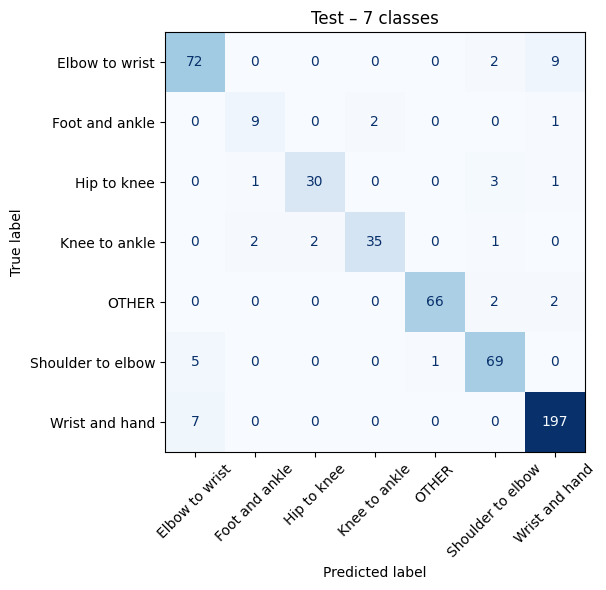

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score

names7 = [SHORT[c] for c in CLASSES]
print(classification_report(y_test, p_test.argmax(1), target_names=names7, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_test.argmax(1)), display_labels=names7).plot(
    ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
ax.set_title('Test – 7 classes'); plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

        HAND      0.973     0.997     0.985       362
         LEG      1.000     0.931     0.964        87
       OTHER      0.985     0.943     0.964        70

    accuracy                          0.979       519
   macro avg      0.986     0.957     0.971       519
weighted avg      0.979     0.979     0.979       519

Balanced accuracy: 0.957
3-class accuracy: 0.979  (95% CI 0.965–0.990)


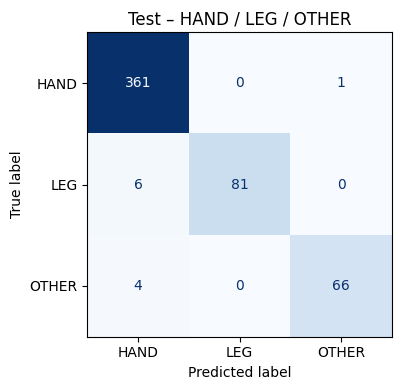

In [12]:
ts, pr = test_out['true_super'], test_out['pred_super']
print(classification_report(ts, pr, labels=SUPER_NAMES, digits=3))
print('Balanced accuracy:', round(balanced_accuracy_score(ts, pr), 3))

correct = (ts == pr).values                          # bootstrap = re-sample the test set 2000 times
rng = np.random.RandomState(SEED)
boot = [correct[rng.randint(0, len(correct), len(correct))].mean() for _ in range(2000)]
print(f'3-class accuracy: {correct.mean():.3f}  (95% CI {np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f})')

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(ts, pr, labels=SUPER_NAMES), display_labels=SUPER_NAMES).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Test – HAND / LEG / OTHER'); plt.tight_layout(); plt.show()

In [13]:
t = test_out.assign(correct7=test_out.label == test_out.pred_label,
                    correct3=test_out.true_super == test_out.pred_super)

print('OTHER, per source:')
print(t[t.label == 'OTHER'].groupby('source').agg(n=('correct3', 'size'), acc_3class=('correct3', 'mean')).round(3))

print('\nAnnotated (coloured marks) vs clean:')
print(t.groupby('has_colour_annotation').agg(n=('correct7', 'size'), acc_7class=('correct7', 'mean'),
                                              acc_3class=('correct3', 'mean')).round(3))

OTHER, per source:
                   n  acc_3class
source                          
Chest_ChestMNIST  56       0.982
Model2_data       14       0.786

Annotated (coloured marks) vs clean:
                         n  acc_7class  acc_3class
has_colour_annotation                             
False                  505       0.921       0.978
True                    14       0.929       1.000


7-class errors: 41 | HAND/LEG/OTHER errors: 11


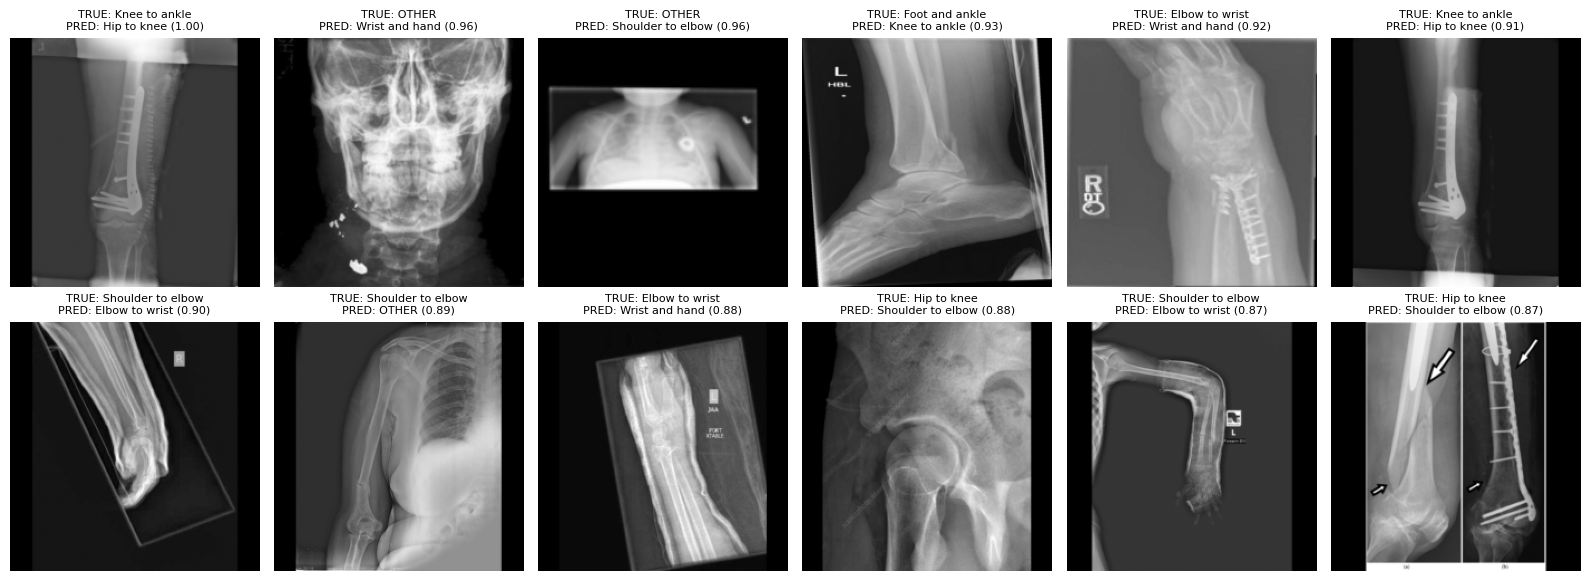

In [14]:
wrong = test_out[test_out.label != test_out.pred_label].copy()
wrong['conf'] = p_test[wrong.index, [CLASSES.index(l) for l in wrong.pred_label]]
wrong = wrong.sort_values('conf', ascending=False).head(12)       # most confident mistakes first
print('7-class errors:', (test_out.label != test_out.pred_label).sum(),
      '| HAND/LEG/OTHER errors:', (test_out.true_super != test_out.pred_super).sum())

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, (_, r) in zip(axes.flat, wrong.iterrows()):
    ax.imshow(X[r.cache_idx], cmap='gray')
    ax.set_title(f'TRUE: {SHORT[r.label]}\nPRED: {SHORT[r.pred_label]} ({r.conf:.2f})', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [15]:
import os
size_mb = os.path.getsize(MODEL_PATH) / 1e6
model.eval(); x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device)
with torch.no_grad():
    for _ in range(10): model(x)                 # warm-up
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(100): model(x)
    torch.cuda.synchronize()
print(f'Model size: {size_mb:.1f} MB | speed: {(time.time() - t0) * 10:.1f} ms per image (batch 1, T4)')

Model size: 17.1 MB | speed: 12.2 ms per image (batch 1, T4)


## Summary – Model 2 v1 (MobileNetV3-Large)
- Test (519 unseen): HAND/LEG/OTHER accuracy 97.9% (95% CI 96.5–99.0), balanced acc 95.7%;
  7-class accuracy 92.1%, macro-F1 0.891. 17.1 MB, 12.2 ms/img (T4). Best epoch 15 (val macro-F1 0.902).
- Errors mostly between neighbouring regions (Elbow-to-wrist ↔ Wrist-and-hand = 16 of 41) → stay within HAND.
- Weak: non-chest OTHER 78.6% (11/14; only 59 training images) → add spine/dental data.
- 6 LEG→HAND errors; possible mislabel seen (knee-ankle with distal-femur plate).
- To check with Grad-CAM: chest shortcut (98.2%), reliance on annotations (only 14 annotated test images).
- Predictions saved: preds_mobilenetv3_{val,test}.csv (for the ensemble).